In [2]:
# Import the libraries we need
import pandas as pd              # tables and data analysis
import numpy as np               # math operations
import matplotlib.pyplot as plt  # basic charts
import seaborn as sns            # nicer charts

# Show ALL columns when printing a table (no "..." in the middle)
pd.set_option("display.max_columns", None)

# Path to the data folder (.. = go up one folder from notebooks/)
DATA = "../data/"

# Load each CSV file into a pandas table (DataFrame)
orders = pd.read_csv(DATA + "olist_orders_dataset.csv")
customers = pd.read_csv(DATA + "olist_customers_dataset.csv")
items = pd.read_csv(DATA + "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA + "olist_order_reviews_dataset.csv")
products = pd.read_csv(DATA + "olist_products_dataset.csv")
sellers = pd.read_csv(DATA + "olist_sellers_dataset.csv")
translation = pd.read_csv(DATA + "product_category_name_translation.csv")

# Show the first 5 rows to see how the table looks
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
import sys
print(sys.executable)

c:\Users\hythm\Documents\olist-dashboard\venv\Scripts\python.exe


In [4]:
# Dictionary: table name -> table, so we can loop over all of them
tables = {
    "orders": orders, "customers": customers, "items": items,
    "payments": payments, "reviews": reviews,
    "products": products, "sellers": sellers,
}

for name, df in tables.items():
    print(f"===== {name} =====")
    print("Shape:", df.shape)                 # (rows, columns)

    missing = df.isna().sum()                 # count of missing values per column
    print("Missing values:")
    print(missing[missing > 0])               # show only columns that have missing values

    print("Duplicated rows:", df.duplicated().sum())  # count of fully duplicated rows
    print()                                   # empty line between tables

===== orders =====
Shape: (99441, 8)
Missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Duplicated rows: 0

===== customers =====
Shape: (99441, 5)
Missing values:
Series([], dtype: int64)
Duplicated rows: 0

===== items =====
Shape: (112650, 7)
Missing values:
Series([], dtype: int64)
Duplicated rows: 0

===== payments =====
Shape: (103886, 5)
Missing values:
Series([], dtype: int64)
Duplicated rows: 0

===== reviews =====
Shape: (99224, 7)
Missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64
Duplicated rows: 0

===== products =====
Shape: (32951, 9)
Missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplicate

In [5]:
# How many orders in each status (delivered, canceled, ...)
print(orders["order_status"].value_counts())
print()

# Keep only orders with no customer delivery date
missing_deliv = orders[orders["order_delivered_customer_date"].isna()]

# What are the statuses of those orders? (to see if missing is expected)
print(missing_deliv["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [6]:
# List of columns that contain dates (currently stored as text)
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

# Convert each column from text to real datetime type
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# Check the data type of every column
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [7]:
# Days from purchase until the customer received the order
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.days

# Actual delivery vs estimated date: positive = late, negative = early
orders["delay_days"] = (
    orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]
).dt.days

# True if the order arrived late
orders["is_late"] = orders["delay_days"] > 0

# Month of purchase (e.g. 2017-10), used for monthly grouping
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M")

# Quick statistical summary to check the new columns look reasonable
orders[["delivery_days", "delay_days", "is_late", "purchase_month"]].describe(include="all")

,delivery_days,delay_days,is_late,purchase_month
count,96476.000000,96476.000000,99441,99441
unique,NaN,NaN,2,25
top,NaN,NaN,False,2017-11
freq,NaN,NaN,92906,7544
mean,12.094086,-11.876881,NaN,NaN
std,9.551746,10.183854,NaN,NaN
min,0.000000,-147.000000,NaN,NaN
25%,6.000000,-17.000000,NaN,NaN
50%,10.000000,-12.000000,NaN,NaN
75%,15.000000,-7.000000,NaN,NaN


In [8]:
# Keep only delivered orders, and drop the 8 anomalies with no delivery date
delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
)

print("Delivered orders:", len(delivered))

# mean of True/False = percentage of late orders (True = 1, False = 0)
print("Late orders %:", round(delivered["is_late"].mean() * 100, 2))
print()

# Delivery time at 50%, 90%, 99% and 100% of orders (to spot outliers)
print(delivered["delivery_days"].quantile([0.5, 0.9, 0.99, 1.0]))

Delivered orders: 96470
Late orders %: 6.77

0.50     10.0
0.90     23.0
0.99     46.0
1.00    209.0
Name: delivery_days, dtype: float64


## Cleaning decisions
- Converted 5 date columns to datetime.
- Dropped 8 "delivered" orders with no delivery date (anomalies).
- Missing delivery dates in other orders are expected (canceled / not shipped).
- 6.77% of delivered orders arrived late.
- Max delivery time is 209 days: rare outlier.

In [9]:
# Size of both tables (items has more rows: one order can have many products)
print(orders.shape)
print(items.shape)

# nunique = count of DIFFERENT values (no repeats)
print("Unique orders in items:", items["order_id"].nunique())
print("Unique customers:", customers["customer_unique_id"].nunique())

(99441, 12)
(112650, 7)
Unique orders in items: 98666
Unique customers: 96096


In [10]:
# Merge orders with customers: both have one row per order, so no duplication
# "on" = the column that links the two tables
df = orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
    on="customer_id",
    how="left",
)

# Check: the number of rows must stay 99441 (same as orders)
print("Rows after merge:", len(df))

# Check: no customer info should be missing
print(df[["customer_unique_id", "customer_state"]].isna().sum())

df.head(3)

Rows after merge: 99441
customer_unique_id    0
customer_state        0
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,is_late,purchase_month,customer_unique_id,customer_state,customer_city
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,-8.0,False,2017-10,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,-6.0,False,2018-07,af07308b275d755c9edb36a90c618231,BA,barreiras
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,-18.0,False,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis


In [11]:
# Total payment per order (payments can have several rows per order)
# groupby = group rows by order_id, then sum the payment value of each group
order_payment = (
    payments.groupby("order_id")["payment_value"]
    .sum()
    .reset_index()
    .rename(columns={"payment_value": "total_payment"})
)

# Total price and number of products per order from the items table
order_items = (
    items.groupby("order_id")
    .agg(total_price=("price", "sum"),
         total_freight=("freight_value", "sum"),
         items_count=("order_item_id", "count"))
    .reset_index()
)

# Review score per order (an order can have more than one review, so we take the mean)
order_review = (
    reviews.groupby("order_id")["review_score"]
    .mean()
    .reset_index()
)

# Each table must have ONE row per order_id: check it
print(len(order_payment), order_payment["order_id"].is_unique)
print(len(order_items), order_items["order_id"].is_unique)
print(len(order_review), order_review["order_id"].is_unique)

99440 True
98666 True
98673 True


In [12]:
# Merge the three summary tables into df, one at a time
# how="left" keeps every order even if it has no payment/items/review
df = (
    df.merge(order_items, on="order_id", how="left")
      .merge(order_payment, on="order_id", how="left")
      .merge(order_review, on="order_id", how="left")
)

# Safety check: rows must still be 99441 (no duplication)
print("Rows after merge:", len(df))
print("order_id unique:", df["order_id"].is_unique)

# Missing values in the new columns
print(df[["total_price", "total_payment", "review_score"]].isna().sum())

df[["order_id", "total_price", "total_freight", "items_count", "total_payment", "review_score"]].head()

Rows after merge: 99441
order_id unique: True
total_price      775
total_payment      1
review_score     768
dtype: int64


,order_id,total_price,total_freight,items_count,total_payment,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,1.0,38.71,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,1.0,141.46,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,1.0,179.12,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,1.0,72.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,1.0,28.62,5.0


In [13]:
# Add the English category name to each product
products_en = products.merge(translation, on="product_category_name", how="left")

# Attach the category to each item row (item level: one row per product in an order)
items_cat = items.merge(
    products_en[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left",
)

# One main category per order: the category of its first item
order_category = (
    items_cat.sort_values("order_item_id")        # make sure item 1 comes first
    .groupby("order_id")["product_category_name_english"]
    .first()                                      # take the first value in each group
    .reset_index()
    .rename(columns={"product_category_name_english": "category"})
)

# Add it to df (left merge keeps all orders)
df = df.merge(order_category, on="order_id", how="left")

print("Rows after merge:", len(df))
print("Missing category:", df["category"].isna().sum())
print(df["category"].value_counts().head(10))

Rows after merge: 99441
Missing category: 2185
category
bed_bath_table           9315
health_beauty            8796
sports_leisure           7683
computers_accessories    6661
furniture_decor          6355
housewares               5836
watches_gifts            5601
telephony                4182
auto                     3881
toys                     3862
Name: count, dtype: int64


In [14]:
# Keep only delivered orders that actually have a delivery date
df_del = df[df["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
)

print("Before:", len(df))
print("After:", len(df_del))

Before: 99441
After: 96470


In [15]:
# Group delivered orders by month: count orders and sum the revenue
monthly = (
    df_del.groupby("purchase_month")
    .agg(orders_count=("order_id", "count"),
         revenue=("total_price", "sum"))
    .reset_index()
)

monthly.head(10)

,purchase_month,orders_count,revenue
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-12,1,10.90
3,2017-01,750,111798.36
4,2017-02,1653,234223.40
5,2017-03,2546,359198.85
6,2017-04,2303,340669.68
7,2017-05,3545,489159.25
8,2017-06,3135,421923.37
9,2017-07,3872,481604.52


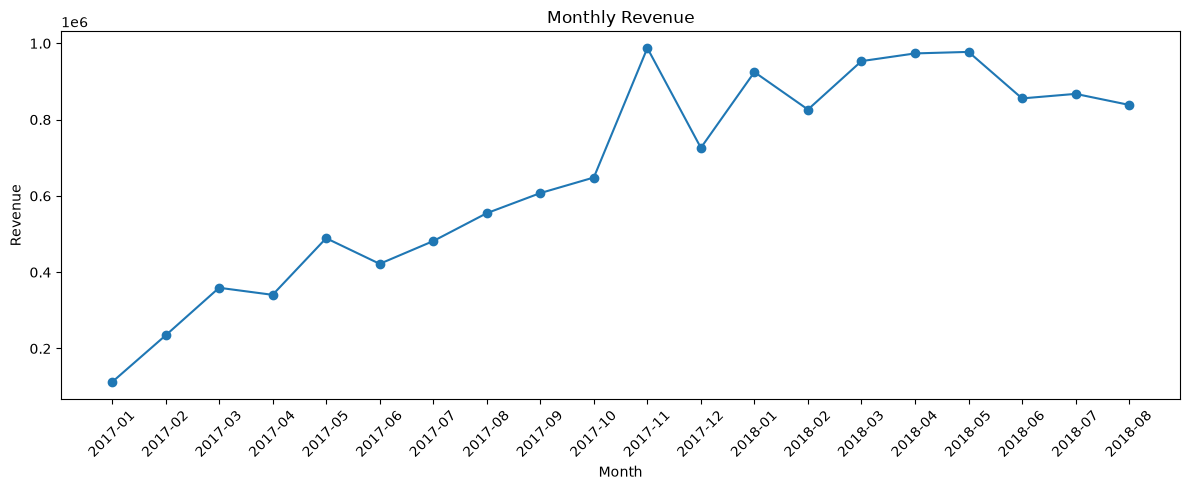

In [16]:
# Keep only months from 2017-01 to 2018-08 (2016 has almost no data)
monthly_plot = monthly[
    (monthly["purchase_month"] >= "2017-01") &
    (monthly["purchase_month"] <= "2018-08")
].copy()

# Convert the month to text so matplotlib can draw it on the x-axis
monthly_plot["month_str"] = monthly_plot["purchase_month"].astype(str)

# Draw a line chart: revenue per month
plt.figure(figsize=(12, 5))
plt.plot(monthly_plot["month_str"], monthly_plot["revenue"], marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [17]:
# Keep only November 2017 orders
nov = df_del[df_del["purchase_month"] == "2017-11"].copy()

# Extract the date (without the time) from the purchase timestamp
nov["purchase_date"] = nov["order_purchase_timestamp"].dt.date

# Count orders per day and show the top 5 busiest days
nov["purchase_date"].value_counts().head(5)

purchase_date
2017-11-24    1147
2017-11-25     487
2017-11-27     395
2017-11-26     382
2017-11-28     371
Name: count, dtype: int64

README: “Black Friday (2017-11-24) produced 1,147 orders in a single day, about 2.4x the next busiest day, driving the November 2017 revenue spike.”

In [18]:
# Group delivered orders by category: count orders and sum revenue
cat_sales = (
    df_del.groupby("category")
    .agg(orders_count=("order_id", "count"),
         revenue=("total_price", "sum"))
    .sort_values("revenue", ascending=False)
    .reset_index()
)

# Show the top 10 categories by revenue
cat_sales.head(10)

,category,orders_count,revenue
0,health_beauty,8608,1232074.12
1,watches_gifts,5470,1163307.35
2,bed_bath_table,9171,1022675.74
3,sports_leisure,7492,956296.76
4,computers_accessories,6501,888589.62
5,furniture_decor,6213,715568.48
6,housewares,5695,618047.37
7,cool_stuff,3531,611525.51
8,auto,3793,579027.59
9,garden_tools,3414,470924.13


In [19]:
# Average revenue per order in each category
cat_sales["avg_order_value"] = cat_sales["revenue"] / cat_sales["orders_count"]

# Show the top 10 categories sorted by average order value
cat_sales.head(10).sort_values("avg_order_value", ascending=False)

,category,orders_count,revenue,avg_order_value
1,watches_gifts,5470,1163307.35,212.670448
7,cool_stuff,3531,611525.51,173.187627
8,auto,3793,579027.59,152.656892
0,health_beauty,8608,1232074.12,143.131287
9,garden_tools,3414,470924.13,137.939112
4,computers_accessories,6501,888589.62,136.685067
3,sports_leisure,7492,956296.76,127.642387
5,furniture_decor,6213,715568.48,115.172780
2,bed_bath_table,9171,1022675.74,111.511911
6,housewares,5695,618047.37,108.524560


## Question 4: Does late delivery reduce customer satisfaction?

**Why it matters:** If late orders get lower review scores, then improving delivery speed is a direct way to improve customer satisfaction.

**Approach:** Split delivered orders into two groups (late vs on-time) and compare their average review score.

**Columns used:** `is_late`, `review_score`

In [20]:
# Keep only orders that have a review score
df_rev = df_del.dropna(subset=["review_score"])

# Average review score and number of orders: late vs on-time
df_rev.groupby("is_late")["review_score"].agg(["mean", "count"])

,mean,count
is_late,,
False,4.290589,89443
True,2.271823,6381


## Question 5: Does the review score drop as the delay gets longer?

**Why it matters:** Knowing whether a short delay is tolerated or any delay hurts helps decide how much to invest in faster delivery.

**Approach:** Group orders by how many days they were late (on time, 1-3, 4-7, more than 7) and compare the average review score of each group.

**Columns used:** `delay_days`, `review_score`

In [21]:
# Split delay_days into groups using pd.cut
# bins = the edges of each group, labels = the name of each group
bins = [-1000, 0, 3, 7, 1000]
labels = ["On time or early", "1-3 days late", "4-7 days late", "More than 7 days late"]
df_rev = df_rev.copy()
df_rev["delay_group"] = pd.cut(df_rev["delay_days"], bins=bins, labels=labels)

# Average review score and number of orders in each group
delay_scores = df_rev.groupby("delay_group", observed=True)["review_score"].agg(["mean", "count"])
delay_scores

,mean,count
delay_group,,
On time or early,4.290589,89443
1-3 days late,3.291037,1852
4-7 days late,2.105549,1748
More than 7 days late,1.697591,2781


## Chart: Average review score by delay group

**Purpose:** Show visually how the review score drops as delivery delay increases.

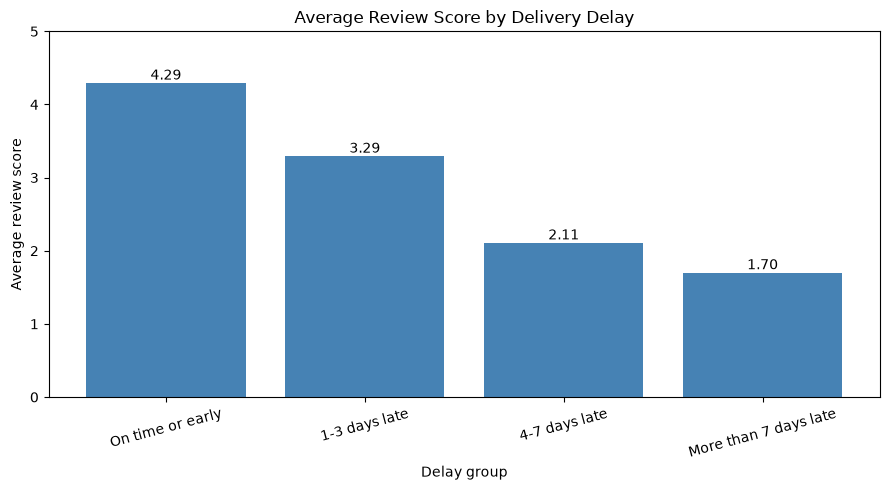

In [22]:
# Draw a bar chart: average review score for each delay group
plt.figure(figsize=(9, 5))
plt.bar(delay_scores.index.astype(str), delay_scores["mean"], color="steelblue")

# Write the score value on top of each bar
for i, value in enumerate(delay_scores["mean"]):
    plt.text(i, value + 0.05, f"{value:.2f}", ha="center")

plt.title("Average Review Score by Delivery Delay")
plt.xlabel("Delay group")
plt.ylabel("Average review score")
plt.ylim(0, 5)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Question 6: Who are our most valuable customers?

**Why it matters:** Not all customers are equal. Knowing who buys recently, often, and spends more helps the business decide who to reward and who to win back.

**Approach:** For each real customer (`customer_unique_id`), calculate Recency (days since last order), Frequency (number of orders), and Monetary (total spent).

**Columns used:** `customer_unique_id`, `order_purchase_timestamp`, `order_id`, `total_payment`

In [23]:
# Reference date = one day after the last order in the data
# (we use it to measure "how many days ago" each customer bought)
snapshot_date = df_del["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# One row per real customer, with 3 numbers: R, F, M
rfm = (
    df_del.groupby("customer_unique_id")
    .agg(recency=("order_purchase_timestamp", lambda x: (snapshot_date - x.max()).days),
         frequency=("order_id", "nunique"),
         monetary=("total_payment", "sum"))
    .reset_index()
)

print("Customers:", len(rfm))
rfm.describe()

Customers: 93350


,recency,frequency,monetary
count,93350.000000,93350.000000,93350.000000
mean,237.950070,1.033423,165.196388
std,152.589932,0.209106,226.322448
min,1.000000,1.000000,0.000000
25%,114.000000,1.000000,63.050000
50%,219.000000,1.000000,107.780000
75%,346.000000,1.000000,182.547500
max,714.000000,15.000000,13664.080000


In [24]:
# Share of customers by number of orders
print("Bought once (%):", round((rfm["frequency"] == 1).mean() * 100, 2))
print("Bought 2+ times (%):", round((rfm["frequency"] >= 2).mean() * 100, 2))

Bought once (%): 97.0
Bought 2+ times (%): 3.0


README: “97% of customers made only one purchase, so the biggest growth opportunity is bringing existing customers back, not only acquiring new ones.”

## Question 7: How can we segment customers into useful groups?

**Why it matters:** Different customers need different marketing actions. Segments let the business target rewards, win-back campaigns, and retention offers.

**Approach:** Score each customer from 1 to 4 on Recency and Monetary using quartiles, then combine the scores into named segments. Frequency is skipped because 97% of customers have the same value (1).

**Columns used:** `recency`, `monetary`

In [25]:
# Score Recency from 1 to 4: recent customers get a HIGH score
# pd.qcut splits customers into 4 equal-sized groups (quartiles)
# labels=[4, 3, 2, 1] because the smallest recency (most recent) should get 4
rfm["r_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)

# Score Monetary from 1 to 4: big spenders get a HIGH score
# rank(method="first") avoids errors when many values are identical
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

# Name the segment based on the two scores
def segment(row):
    if row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Champions"
    elif row["r_score"] >= 3:
        return "Promising"
    elif row["m_score"] >= 3:
        return "Big spenders at risk"
    else:
        return "Low value"

rfm["segment"] = rfm.apply(segment, axis=1)

# Size and average values of each segment
rfm.groupby("segment").agg(
    customers=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_monetary=("monetary", "mean"),
).round(1)

,customers,avg_recency,avg_monetary
segment,,,
Big spenders at risk,22759,364.1,267.7
Champions,23916,112.1,266.0
Low value,23750,365.2,64.0
Promising,22925,112.3,63.1


README: “22,759 customers (about 24%) spent an average of 268 but have not purchased in about a year. Win-back campaigns targeting this segment offer the highest return.”

## Chart: Customer segments, size and average spend

**Purpose:** Show how many customers are in each segment and how much each segment spends on average, to support the win-back recommendation.

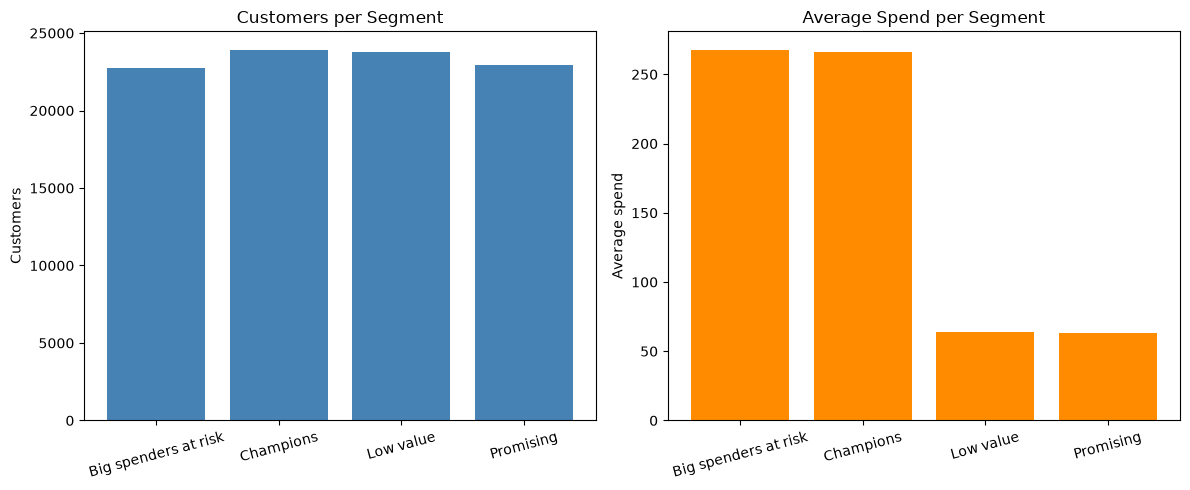

In [26]:
# Build a small table: one row per segment
seg = (
    rfm.groupby("segment")
    .agg(customers=("customer_unique_id", "count"),
         avg_monetary=("monetary", "mean"))
    .sort_values("avg_monetary", ascending=False)
)

# Create one figure with 2 charts side by side (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left chart: number of customers in each segment
axes[0].bar(seg.index, seg["customers"], color="steelblue")
axes[0].set_title("Customers per Segment")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=15)

# Right chart: average spend in each segment
axes[1].bar(seg.index, seg["avg_monetary"], color="darkorange")
axes[1].set_title("Average Spend per Segment")
axes[1].set_ylabel("Average spend")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("../app/segments.png", dpi=150)
plt.show()

## Export: Save cleaned data for the dashboard

**Purpose:** Save the final tables as CSV files so the Streamlit app can load them directly without repeating the cleaning steps.

In [27]:
# Choose only the columns the dashboard needs (keeps the files small)
orders_out = df_del[[
    "order_id", "customer_unique_id", "customer_state",
    "order_purchase_timestamp", "purchase_month",
    "delivery_days", "delay_days", "is_late",
    "total_price", "total_payment", "review_score", "category",
]].copy()

# Month as text, because CSV files cannot store the Period type
orders_out["purchase_month"] = orders_out["purchase_month"].astype(str)

# index=False means: do not write the row numbers into the file
orders_out.to_csv("../app/orders_clean.csv", index=False)
rfm.to_csv("../app/rfm.csv", index=False)

print("orders_clean:", orders_out.shape)
print("rfm:", rfm.shape)

orders_clean: (96470, 12)
rfm: (93350, 7)
